# Controle seletivo: quem assume a bomba?

Controlar a vazão e manter água suficiente na sucção da bomba. Quando os objetivos entram em conflito, **um seletor decide qual controlador assume**.

Execute em ordem. A teoria e o artigo estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/05_controle_seletivo/README.md).

In [1]:
%pip -q install control==0.10.2 numpy scipy matplotlib ipywidgets

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
import control as controle
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

## O processo

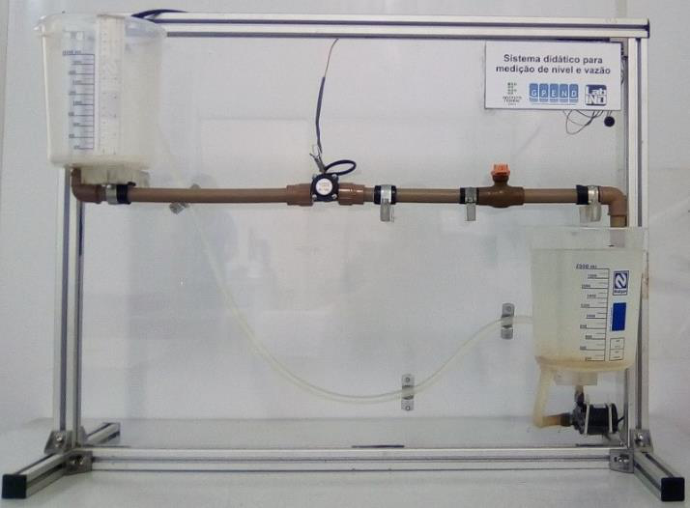

A bomba devolve água ao reservatório de sucção. Aumentar seu comando aumenta a vazão de retorno **e** o nível. Por isso, nível baixo pede um comando maior; neste caso, usar **MAX**, não MIN.

Trabalhar com variações em torno de uma condição inicial.

## Os modelos

\[
G_h(s)=\frac{0{,}1693}{54{,}813s+1},\qquad
G_q(s)=\frac{0{,}0252e^{-4{,}024s}}{49{,}756s+1}.
\]

O tempo está em segundos; as saídas são cm e L/min. A entrada é uma unidade de comando PWM, cuja escala absoluta não foi informada. Os modelos são locais; condições iniciais e limites de comando são didáticos.

In [3]:
modelos = {
    "nivel": {"ganho": 0.1693, "tempo": 54.813, "atraso": 0.0},
    "vazao": {"ganho": 0.0252, "tempo": 49.756, "atraso": 4.024},
}
nivel_inicial, vazao_inicial = 8.6, 2.45
limite_comando = 40.0  # Variação de PWM; não é uma porcentagem da bomba.

In [4]:
def resposta_modelo(tempo, entrada, ganho, constante, atraso):
    passo = tempo[1] - tempo[0]
    entrada_atrasada = np.interp(tempo - atraso, tempo, entrada, left=0)
    fator = np.exp(-passo / constante)
    saida = np.zeros_like(tempo)
    for indice in range(len(tempo) - 1):
        saida[indice + 1] = (fator * saida[indice]
                            + (1 - fator) * ganho * entrada_atrasada[indice])
    return saida

## Obter os dados do ensaio

Guardar **tempo, entrada e saída medida** depois de estimular a planta. Separar três ensaios com ruído: **ajuste**, **escolha** e **validação**. Os dados abaixo são simulados a partir dos modelos publicados.

Para usar dados próprios, enviar os CSVs a `dados_ensaio/` e mudar `usar_ensaio_externo` para `True`. Usar colunas `tempo,entrada,saida`, amostragem uniforme e desvios do ponto de operação, começando em equilíbrio. Manter a unidade de tempo e as escalas do canal.

In [5]:
from pathlib import Path
from scipy import signal
from scipy.optimize import least_squares

def guardar_ensaio(nome, tempo, entrada, saida):
    pasta = Path('dados_ensaio')
    pasta.mkdir(exist_ok=True)
    np.savetxt(pasta / f'{nome}.csv', np.column_stack([tempo, entrada, saida]),
               delimiter=',', header='tempo,entrada,saida', comments='')

In [6]:
usar_ensaio_externo = False
intensidade_ruido = 1.0  # Alterar o ruído e repetir os três ensaios.
desvios_ruido = {'nivel': .04, 'vazao': .01}
if not usar_ensaio_externo:
    tempo_ensaio = np.arange(0, 500.5, .5)
    entradas = {
        'ajuste': np.where(tempo_ensaio >= 30, 12., 0.),
        'escolha': np.select([tempo_ensaio < 30, tempo_ensaio < 160,
                             tempo_ensaio < 310], [0., -8., 10.], default=4.),
        'validacao': np.select([tempo_ensaio < 50, tempo_ensaio < 180,
                               tempo_ensaio < 350], [0., 6., -10.], default=8.)}
    for numero, (etapa, entrada) in enumerate(entradas.items()):
        gerador = np.random.default_rng(42 + numero)
        for canal, modelo in modelos.items():
            saida = resposta_modelo(tempo_ensaio, entrada, *modelo.values())
            medicao = saida + gerador.normal(0, desvios_ruido[canal]*intensidade_ruido, len(saida))
            guardar_ensaio(f'{etapa}_{canal}', tempo_ensaio, entrada, medicao)
print('Ler dados_ensaio/{ajuste,escolha,validacao}_{nivel,vazao}.csv.')

Ler dados_ensaio/{ajuste,escolha,validacao}_{nivel,vazao}.csv.


## Ler os dados

Separar a planta dos arquivos de identificação. O ajuste receberá somente os sinais lidos dos CSVs.

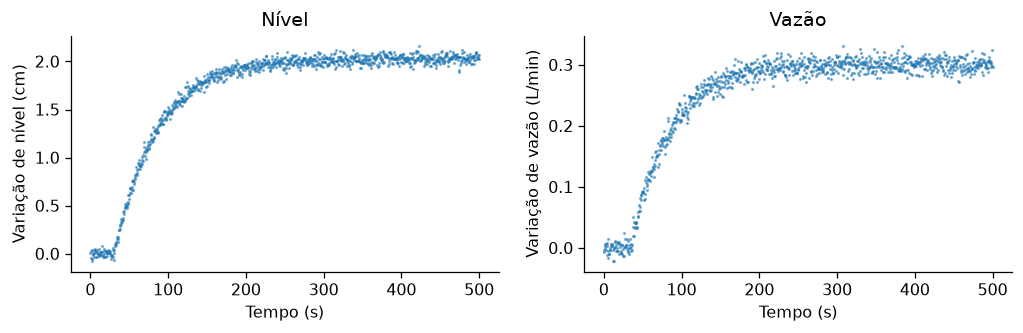

In [7]:
def ler_ensaio(nome):
    dados = np.genfromtxt(Path('dados_ensaio') / f'{nome}.csv', delimiter=',', names=True)
    tempo, entrada, saida = [np.asarray(dados[c], float) for c in ('tempo', 'entrada', 'saida')]
    if len(tempo) < 20 or not np.all(np.isfinite([tempo, entrada, saida])):
        raise ValueError('Fornecer pelo menos 20 amostras finitas de tempo, entrada e saída.')
    if not np.all(np.diff(tempo) > 0) or not np.allclose(np.diff(tempo), np.diff(tempo)[0]):
        raise ValueError('Usar amostragem uniforme, com tempo crescente.')
    if abs(entrada[0]) > 1e-10:
        raise ValueError('Remover o ponto de operação da entrada; iniciar em desvio zero.')
    return tempo - tempo[0], entrada, saida

canais = ['nivel', 'vazao']
nomes_canais = {'nivel': 'Nível', 'vazao': 'Vazão'}
unidades = {'tempo': 'Tempo (s)', 'nivel': 'Variação de nível (cm)', 'vazao': 'Variação de vazão (L/min)'}
ensaios = {canal: {etapa: ler_ensaio(f'{etapa}_{canal}')
                    for etapa in ('ajuste', 'escolha', 'validacao')} for canal in canais}
figura, eixos = plt.subplots(1, len(canais), figsize=(9, 3), squeeze=False)
for canal, eixo in zip(canais, eixos.ravel()):
    tempo, entrada, saida = ensaios[canal]['ajuste']
    eixo.plot(tempo, saida, '.', ms=2, alpha=.5)
    eixo.set(title=nomes_canais[canal], xlabel=unidades['tempo'], ylabel=unidades[canal])
plt.tight_layout(); plt.show()

## Identificar P1D, P2D ou P3D

Comparar um, dois ou três **polos reais estáveis** e um **atraso estimado** (D): $\widehat G=K e^{-\theta s}/\prod_i(\tau_i s+1)$. São 3, 4 e 5 parâmetros, respectivamente. Ajustar somente no primeiro ensaio; não informar os parâmetros publicados ao identificador.

In [8]:
def prever_modelo(modelo, ensaio):
    tempo, entrada, _ = ensaio
    denominador = np.array([1.0])
    for constante in modelo['constantes']:
        denominador = np.convolve(denominador, [constante, 1.0])
    entrada_atrasada = np.interp(tempo - modelo['atraso'], tempo, entrada, left=0)
    numerador, denominador, _ = signal.cont2discrete(
        ([modelo['ganho']], denominador), tempo[1] - tempo[0], method='zoh')
    return signal.lfilter(numerador.ravel(), denominador, entrada_atrasada)

def avaliar_modelo(modelo, ensaio):
    previsao = prever_modelo(modelo, ensaio)
    erro = ensaio[2] - previsao
    escala = np.linalg.norm(ensaio[2] - np.mean(ensaio[2]))
    ajuste = 100 * (1 - np.linalg.norm(erro) / escala) if escala > 0 else np.nan
    return ajuste, np.sqrt(np.mean(erro ** 2))

In [9]:
def identificar_modelo(ensaio, ordem):
    tempo, entrada, saida = ensaio
    duracao, passo = tempo[-1], tempo[1] - tempo[0]
    cauda = slice(-max(10, len(tempo) // 10), None)
    ganho_inicial = abs(np.median(saida[cauda]) / np.median(entrada[cauda]))
    if not np.isfinite(ganho_inicial) or ganho_inicial <= 0:
        raise ValueError('Usar um ensaio de ajuste com patamar final diferente de zero.')
    def montar(parametros):
        return {'ganho': parametros[0], 'constantes': np.sort(parametros[1:-1]),
                'atraso': parametros[-1], 'parametros': ordem + 2}
    limites = ([ganho_inicial / 20] + [passo / 10] * ordem + [0],
               [ganho_inicial * 20] + [duracao * 2] * ordem + [duracao / 4])
    ajustes = []
    for fracao in (0.06, 0.18):
        constantes = (np.geomspace(max(passo / 5, duracao * 0.002), duracao * fracao, ordem)
                      if ordem > 1 else [duracao * fracao])
        inicio = [ganho_inicial, *constantes, passo]
        ajuste = least_squares(lambda p: prever_modelo(montar(p), ensaio) - saida,
                               inicio, bounds=limites, x_scale='jac', max_nfev=250)
        ajustes.append(ajuste)
    melhor = min(ajustes, key=lambda resultado: resultado.cost)
    if not melhor.success:
        raise RuntimeError('O ajuste não convergiu; revisar o ensaio antes da sintonia.')
    return montar(melhor.x)

In [10]:
candidatos_modelo = {canal: {f'P{ordem}D': identificar_modelo(ensaios[canal]['ajuste'], ordem)
                             for ordem in (1, 2, 3)} for canal in canais}

## Escolher com parcimônia

Prever o segundo ensaio sem reajustar. Entre os modelos até **1 ponto percentual** do melhor FIT, escolher o de menos parâmetros. A tolerância é uma escolha didática, não um teste estatístico. FIT pode ser negativo.

In [11]:
def escolher_modelo(candidatos, ensaio_escolha, tolerancia=1.0):
    ajustes = {nome: avaliar_modelo(modelo, ensaio_escolha)[0]
               for nome, modelo in candidatos.items()}
    melhor = max(ajustes.values())
    elegiveis = [nome for nome in candidatos if ajustes[nome] >= melhor - tolerancia]
    return min(elegiveis, key=lambda nome: (candidatos[nome]['parametros'], -ajustes[nome]))

def reduzir_modelo(modelo):
    return np.array([modelo['ganho'], np.sum(modelo['constantes']), modelo['atraso']])

In [12]:
selecionados = {canal: escolher_modelo(candidatos_modelo[canal], ensaios[canal]['escolha'])
                for canal in canais}
print(f"{'Canal':<12}{'Modelo':<9}{'Parâmetros':>12}{'FIT escolha (%)':>18}  Seleção")
for canal in canais:
    for nome, modelo in candidatos_modelo[canal].items():
        ajuste = avaliar_modelo(modelo, ensaios[canal]['escolha'])[0]
        marca = '← parcimonioso' if nome == selecionados[canal] else ''
        print(f"{canal:<12}{nome:<9}{modelo['parametros']:>12}{ajuste:>18.2f}  {marca}")
modelos_reduzidos = {canal: reduzir_modelo(candidatos_modelo[canal][selecionados[canal]])
                    for canal in canais}

Canal       Modelo     Parâmetros   FIT escolha (%)  Seleção
nivel       P1D                 3             95.32  ← parcimonioso
nivel       P2D                 4             95.32  
nivel       P3D                 5             95.32  
vazao       P1D                 3             92.49  ← parcimonioso
vazao       P2D                 4             92.49  
vazao       P3D                 5             92.49  


## Validar sem reajustar

Usar o terceiro ensaio somente depois da escolha. Conferir a previsão e o erro na unidade da saída. Não refazer o ajuste com esses dados.

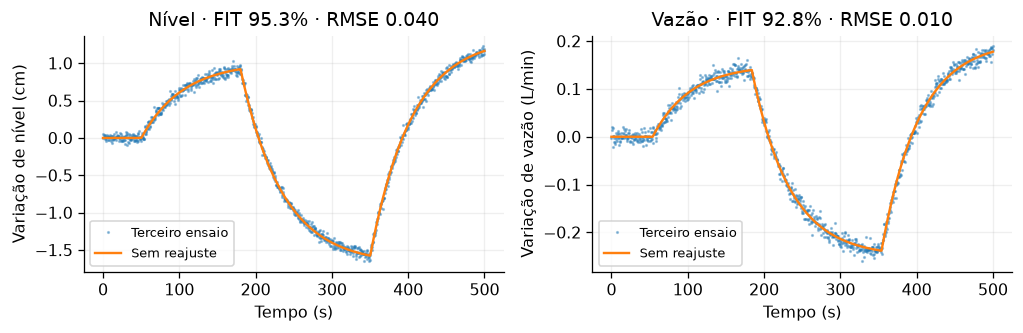

In [13]:
figura, eixos = plt.subplots(1, len(canais), figsize=(9, 3), squeeze=False)
erros_validacao = {}
for canal, eixo in zip(canais, eixos.ravel()):
    ensaio = ensaios[canal]['validacao']
    modelo = candidatos_modelo[canal][selecionados[canal]]
    ajuste, rmse = avaliar_modelo(modelo, ensaio)
    erros_validacao[canal] = rmse
    eixo.plot(ensaio[0], ensaio[2], '.', ms=2, alpha=.4, label='Terceiro ensaio')
    eixo.plot(ensaio[0], prever_modelo(modelo, ensaio), label='Sem reajuste')
    eixo.set(title=f'{nomes_canais[canal]} · FIT {ajuste:.1f}% · RMSE {rmse:.3f}',
             xlabel=unidades['tempo'], ylabel=unidades[canal])
    eixo.legend(fontsize=8); eixo.grid(alpha=.2)
plt.tight_layout(); plt.show()

## Sintonizar por IMC

Para P2D/P3D, usar $\tau_{eq}=\sum_i\tau_i$ como aproximação de primeira ordem, mantendo ganho e atraso.

A correlação IMC do artigo é $K_c=(2\tau_{eq}+\theta)/(2K\lambda)$ e $T_i=\tau_{eq}+\theta/2$. Usar $\lambda=\tau_{eq}$ no painel final. Cada controlador calcula uma proposta; a seleção virá depois.

In [14]:
def sintonia_imc(modelo, tempo_desejado=None):
    ganho, constante, atraso = modelo['ganho'], modelo['tempo'], modelo['atraso']
    if tempo_desejado is None:
        tempo_desejado = constante
    return {'proporcional': (2*constante + atraso)/(2*ganho*tempo_desejado),
            'integral': constante + atraso/2, 'rastreamento': tempo_desejado}

identificados = {canal: dict(zip(['ganho','tempo','atraso'], parametros))
                 for canal, parametros in modelos_reduzidos.items()}
controladores = {nome: sintonia_imc(modelo) for nome, modelo in identificados.items()}
for nome, parametros in controladores.items():
    print(f"PI de {nome}: Kc={parametros['proporcional']:.3f}; Ti={parametros['integral']:.2f} s")

PI de nivel: Kc=5.923; Ti=54.68 s
PI de vazao: Kc=41.460; Ti=51.39 s


## Comparar as sintonias

Escolher o canal e comparar a sintonia de outra estrutura com a parcimoniosa. Manter a mesma planta e o mesmo λ nas duas curvas. A pré-simulação fecha uma malha de cada vez; o seletor ainda não atua. No painel final, manter λ igual a τeq de cada canal.

In [15]:
def comparar_sintonias(canal='vazao', estrutura='P2D', tempo_imc=50.):
    planta = modelos[canal]
    atraso = controle.tf(*controle.pade(planta['atraso'], 3))
    processo = controle.tf([planta['ganho']], [planta['tempo'], 1]) * atraso
    tempo = np.linspace(0, 400, 501)
    plt.figure(figsize=(8, 3))
    for nome in dict.fromkeys([selecionados[canal], estrutura]):
        parametros = dict(zip(['ganho','tempo','atraso'], reduzir_modelo(candidatos_modelo[canal][nome])))
        sintonia = sintonia_imc(parametros, tempo_imc)
        controlador = sintonia['proporcional'] * controle.tf([sintonia['integral'], 1], [sintonia['integral'], 0])
        malha = controle.feedback(controlador * processo)
        if np.any(controle.poles(malha).real >= 0):
            print(f'{nome}: malha instável; aumentar λ.'); continue
        resposta = controle.step_response(malha, tempo).outputs
        plt.plot(tempo, resposta, label=nome)
        print(f"{nome}: Kc={sintonia['proporcional']:.3f}; Ti={sintonia['integral']:.2f} s")
    plt.axhline(1, color='gray', ls=':', label='Referência: variação de 1 na saída')
    plt.xlabel('Tempo (s)'); plt.ylabel(unidades[canal]); plt.legend(); plt.grid(alpha=.2); plt.show()

widgets.interact(comparar_sintonias,
    canal=widgets.Dropdown(options=[('Nível','nivel'),('Vazão','vazao')], value='vazao', description='Canal'),
    estrutura=widgets.Dropdown(options=['P1D','P2D','P3D'], value='P2D', description='Comparar'),
    tempo_imc=widgets.FloatSlider(value=50, min=40, max=120, step=10,
        description='IMC λ (s)', continuous_update=False));

interactive(children=(Dropdown(description='Canal', index=1, options=(('Nível', 'nivel'), ('Vazão', 'vazao')),…

## A decisão principal

Os PI calculam dois comandos para **a mesma bomba**. Se o nível pedir mais comando, ele assume. A vazão pode então se afastar da referência. Esse é o diferencial desta estratégia: **priorizar uma restrição**, em vez de atender simultaneamente a objetivos incompatíveis.

In [16]:
def selecionar_comando(comando_vazao, comando_nivel):
    return max(comando_vazao, comando_nivel)

comando_vazao, comando_nivel = -30., -21.
print("Só vazão:", comando_vazao)
print("Com seletor MAX:", selecionar_comando(comando_vazao, comando_nivel))

Só vazão: -30.0
Com seletor MAX: -21.0


## A simulação

Os modelos publicados representam a planta; os estimados sintonizam os PI. O controlador não selecionado acompanha o comando aplicado, evitando acumular integral sem atuar.

Reduzir a referência de vazão após 400 s. As curvas mostram as respostas do modelo; o ruído entra nas medições usadas pelos PI.

In [17]:
def simular(vazao_final=1.8, nivel_minimo=5., ruido=1., seletor=True, passo=.5):
    tempo = np.arange(0, 1000 + passo / 2, passo)
    quantidade = len(tempo)
    nivel, vazao, comando = (np.zeros(quantidade) for _ in range(3))
    candidatos = np.zeros((quantidade, 2))
    nivel_selecionado = np.zeros(quantidade, dtype=bool)
    referencia = np.where(tempo < 400, 2.6, vazao_final)
    integrais = {"nivel": 0., "vazao": 0.}
    gerador = np.random.default_rng(7)
    ruido_nivel = gerador.normal(0, .04 * ruido, quantidade)
    ruido_vazao = gerador.normal(0, .01 * ruido, quantidade)
    for indice in range(quantidade - 1):
        erros = {"nivel": nivel_minimo - nivel_inicial - nivel[indice] - ruido_nivel[indice],
                 "vazao": referencia[indice] - vazao_inicial - vazao[indice] - ruido_vazao[indice]}
        propostas = {nome: controladores[nome]["proporcional"] * erros[nome]
                     + integrais[nome] for nome in integrais}
        candidatos[indice] = [propostas["vazao"], propostas["nivel"]]
        escolhido = (selecionar_comando(*candidatos[indice]) if seletor
                     else propostas["vazao"])
        comando[indice] = np.clip(escolhido, -limite_comando, limite_comando)
        nivel_selecionado[indice] = seletor and propostas["nivel"] > propostas["vazao"]
        for nome in integrais:
            parametros = controladores[nome]
            integrais[nome] += passo * (
                parametros["proporcional"] * erros[nome] / parametros["integral"]
                + (comando[indice] - propostas[nome]) / parametros["rastreamento"])
        # Cada passo atualiza uma função de transferência de primeira ordem.
        for nome, saida in [("nivel", nivel), ("vazao", vazao)]:
            modelo = modelos[nome]
            entrada = np.interp(tempo[indice] - modelo["atraso"], tempo[:indice + 1],
                                comando[:indice + 1], left=0.)
            fator = np.exp(-passo / modelo["tempo"])
            saida[indice + 1] = fator * saida[indice] + (1 - fator) * modelo["ganho"] * entrada
    comando[-1], candidatos[-1] = comando[-2], candidatos[-2]
    nivel_selecionado[-1] = nivel_selecionado[-2]
    return {"tempo": tempo, "nivel": nivel + nivel_inicial,
            "vazao": vazao + vazao_inicial, "comando": comando,
            "candidatos": candidatos, "nivel_selecionado": nivel_selecionado,
            "referencia": referencia}

In [18]:
def painel(vazao_final=1.8, nivel_minimo=5., ruido=1.):
    simples = simular(vazao_final, nivel_minimo, ruido, seletor=False)
    seletivo = simular(vazao_final, nivel_minimo, ruido, seletor=True)
    tempo = seletivo["tempo"]
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
    for eixo, variavel, unidade in zip(eixos, ["nivel", "vazao"], ["cm", "L/min"]):
        eixo.plot(tempo, simples[variavel], label="Só vazão", color="#3975c5")
        eixo.plot(tempo, seletivo[variavel], label="Seletor MAX", color="#16806a")
        eixo.set(ylabel=f"{variavel.capitalize()} ({unidade})")
        eixo.grid(alpha=.2)
    eixos[0].axhline(nivel_minimo, color="#c34f35", linestyle="--", label="Limite de nível")
    eixos[1].plot(tempo, seletivo["referencia"], "k--", label="Referência de vazão")
    eixos[1].plot(tempo, np.where(seletivo["nivel_selecionado"], seletivo["vazao"], np.nan),
                  color="#d78929", linewidth=3, label="Nível assumiu")
    for eixo in eixos:
        eixo.legend(loc="best", ncol=2, fontsize=9)
    eixos[1].set(xlabel="Tempo (s)")
    plt.show()
    print(f"Final com MAX: nível {seletivo['nivel'][-1]:.2f} cm; "
          f"vazão {seletivo['vazao'][-1]:.2f} L/min. Observe o trecho laranja.")

widgets.interact(painel,
    vazao_final=widgets.FloatSlider(value=1.8, min=1.6, max=2.5, step=.1,
                                   description="Vazão final", continuous_update=False),
    nivel_minimo=widgets.FloatSlider(value=5., min=4.5, max=7., step=.5,
                                    description="Nível mínimo", continuous_update=False),
    ruido=widgets.FloatSlider(value=1., min=0., max=3., step=.5,
                              description="Ruído ×", continuous_update=False));

interactive(children=(FloatSlider(value=1.8, continuous_update=False, description='Vazão final', max=2.5, min=…

## Experimente

1. Use vazão final **2,5 L/min**: os objetivos deixam de competir.
2. Volte para **1,8 L/min**: observe quem assume e o erro de vazão aceito.
3. Aumente o nível mínimo; depois, o ruído. A seleção muda?

O limite é um objetivo de controle, não uma barreira garantida. Ruído e dinâmica podem causar pequenas passagens temporárias.

## Referências

SILVA, G. R. S.; JESUS, L. F. F. S. [Avaliação de estratégia de controle override em um módulo didático de vazão e nível](https://www.confea.org.br/midias/uploads-imce/Contecc2019/Experi%C3%AAncia%20Profissional/AVALIA%C3%87%C3%83O%20DE%20ESTRATEGIA%20DE%20CONTROLE%20OVERRIDE%20EM%20UM%20MODULO%20DIDATICO%20DE%20VAZ%C3%83O%20E%20NIVEL.pdf). CONTECC, 2019. Modelos: Tabela 2; sintonia IMC: Tabela 1; fotografia: Figura 2, recortada.